# Eigenzustands-Thermalisierung

Das Notebook diagonalisiert die Mixed-Field-Ising-Kette exakt (bis 13 Qubits, getrennt nach Symmetriesektoren) und prüft die Hypothese der Eigenzustands-Thermalisierung (ETH) an der Observablen $X$ in der Kettenmitte: Diagonalelemente gegen das kanonische Ensemble, das Schrumpfen ihrer Schwankungen mit der Systemgröße, Größe und Verteilung der Nichtdiagonalelemente und den Langzeitwert nach Quenches aus 60 zufälligen Produktzuständen, jeweils für die chaotische und die integrable Kette.

Warum sieht ein einzelner Energieeigenzustand eines chaotischen Vielteilchensystems für jede lokale Messung aus wie ein thermischer Zustand, und warum gilt das in integrablen Systemen nicht?

#### **Hintergrund**

Die statistische Physik beschreibt ein System im Gleichgewicht mit wenigen Zahlen, etwa Energie und Temperatur, und vergisst alle Details des Anfangszustands. Für ein abgeschlossenes Quantensystem ist das zunächst ein Rätsel: Die Zeitentwicklung ist unitär, ein reiner Zustand bleibt rein, und die Information über den Anfang geht nie verloren. Trotzdem relaxieren lokale Größen in Experimenten mit kalten Atomen, gefangenen Ionen und Qubits auf thermische Werte. Deutsch (1991) und Srednicki (1994) haben die Auflösung vorgeschlagen: Die Thermalisierung steckt schon in jedem einzelnen Energieeigenzustand. Rigol, Dunjko und Olshanii (2008) haben das zum ersten Mal in einem Vielteilchensystem numerisch gezeigt.

Diese **Hypothese der Eigenzustands-Thermalisierung** (ETH) ist das Bindeglied zwischen den drei Blickwinkeln auf Quantenchaos in dieser Serie: Sie erklärt, warum chaotische Spektren wie Zufallsmatrizen aussehen ([Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb)), warum Operatoren wachsen und OTOCs zerfallen und warum Eigenzustände so stark verschränkt sind wie Zufallszustände, die Page-Kurve ([Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb)). Integrable Systeme verletzen die ETH, weil sie zu viele Erhaltungsgrößen haben, und relaxieren nur auf ein verallgemeinertes Gibbs-Ensemble. Das wurde 2006 im „Quanten-Newton-Pendel“ von Kinoshita, Wenger und Weiss mit eindimensionalen Bose-Gasen beobachtet, die nach tausenden Stößen nicht thermalisierten.

Das Notebook nimmt dieselbe Ising-Kette wie die beiden anderen Notebooks der Serie ($J = h_x = 1$; chaotisch bei $h_z = 0.5$, integrabel bei $h_z = 0$) und als Observable $A = X$ auf dem mittleren Qubit.

Landkarte:

- **Eigenzustände**
  - Diagonalelemente (Exp. 1): In der chaotischen Kette liegen die $\langle n\vert A\vert n\rangle$ in einem schmalen Band um die kanonische Kurve; in der integrablen auf getrennten Ästen, keine glatte Funktion der Energie.
  - Schwankungen gegen die Systemgröße (Exp. 2): chaotisch schrumpfen sie wie $D^{-1/2} = e^{-S/2}$ (Steigung −0.48), integrabel bleiben sie bei 0.37 bis 0.40.
  - Nichtdiagonalelemente (Exp. 3): chaotisch eine glatte Funktion $\vert f(\omega)\vert^2$ und gaußverteilt ($\Gamma = 1.57 = \pi/2$); integrabel sind über 97 % exakt null.
- **Dynamik**
  - Quench aus 60 zufälligen Produktzuständen (Exp. 4): Der Langzeitwert der chaotischen Kette weicht höchstens um 0.009 vom thermischen Wert ab, der der integrablen bis zu 0.10.

Verwandte Notebooks: [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb) (Niveauabstoßung derselben Kette), [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb) (OTOCs, Page-Kurve), [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb) (GOE und Gaußverteilung der Eigenvektoren), [Quanteninformationstheorie und Abstandsmaße](https://github.com/deltorobarba/science/blob/main/quantum/quantuminformation.ipynb) (Entropien, Gibbs-Zustände).

#### **Theorie**

##### *1. Thermalisierung in einem abgeschlossenen System*

Ein abgeschlossenes System im reinen Zustand $\vert\psi(0)\rangle = \sum_n c_n\vert n\rangle$ (Entwicklung in Energieeigenzuständen $\vert n\rangle$ mit Energien $E_n$) entwickelt sich unitär, $\vert\psi(t)\rangle = \sum_n c_ne^{-iE_nt}\vert n\rangle$. Der Erwartungswert einer Observablen $A$ ist
$$\langle A(t)\rangle = \sum_n \vert c_n\vert^2 A_{nn} + \sum_{m\ne n} c_m^\ast c_n\,e^{i(E_m - E_n)t}A_{mn}, \qquad A_{mn} = \langle m\vert A\vert n\rangle .$$
Sind alle Energiedifferenzen verschieden, heben sich die Phasen des zweiten Terms im Zeitmittel auf. Übrig bleibt das **diagonale Ensemble**
$$\overline{\langle A\rangle} = \sum_n \vert c_n\vert^2 A_{nn} ,$$
das noch alle Gewichte $\vert c_n\vert^2$ des Anfangszustands enthält, $2^N$ Zahlen. **Thermalisierung** heißt: Dieser Langzeitwert hängt nur von der Energie des Anfangszustands ab und stimmt mit dem thermischen Wert überein, und die Schwankungen um ihn sind klein. Das gilt nur für **lokale Observablen**, die wenige Qubits betreffen; der globale Zustand bleibt rein und erinnert sich an alles.

##### *2. Ensembles und Temperatur*

- **Mikrokanonisch:** der Mittelwert über alle Eigenzustände in einem schmalen Energiefenster.
- **Kanonisch:** $\langle A\rangle_\beta = \mathrm{Tr}(A\,e^{-\beta H})/\mathrm{Tr}\,e^{-\beta H}$ mit der inversen Temperatur $\beta = 1/k_BT$. Zu jeder Energie $E$ gehört das $\beta(E)$, bei dem $\langle H\rangle_\beta = E$ gilt. Für große Systeme geben beide Ensembles dieselben lokalen Werte (**Äquivalenz der Ensembles**); bei 13 Qubits unterscheiden sie sich noch um einige Prozent.
- **Unendliche Temperatur** $\beta = 0$: alle Zustände gleich gewichtet, Energie $\mathrm{Tr}\,H/2^N = 0$ in der Mitte des Spektrums. Weil das Spektrum einer Spinkette nach oben beschränkt ist, gehört zu Energien oberhalb der Mitte eine **negative Temperatur** ($\beta < 0$).

Die Ensemble-Mittel werden hier exakt aus allen $2^{13}$ Eigenwerten berechnet; weil $A$ mit allen Symmetrien vertauscht, zerfällt die Spur in die Beiträge der Sektoren.

##### *3. Die Hypothese der Eigenzustands-Thermalisierung*

In einem chaotischen System haben die Matrixelemente einer lokalen Observablen in der Energieeigenbasis die Form
$$A_{mn} = \mathcal A(\bar E)\,\delta_{mn} + e^{-S(\bar E)/2}\,f_A(\bar E, \omega)\,R_{mn}, \qquad \bar E = \frac{E_m + E_n}{2},\quad \omega = E_m - E_n .$$
- $\mathcal A(\bar E)$ ist eine **glatte Funktion der Energie**, gleich dem mikrokanonischen Mittelwert.
- $S(\bar E)$ ist die thermodynamische Entropie, $e^{S}$ die Zahl der Zustände in einem Energiefenster; $e^{-S/2}$ ist also exponentiell klein in der Systemgröße.
- $f_A(\bar E, \omega)$ ist eine weitere **glatte Funktion**, die festlegt, welche Frequenzen in der Dynamik von $A$ vorkommen.
- $R_{mn}$ sind Zufallszahlen mit Mittelwert 0 und Varianz 1, für reelle Hamiltonoperatoren reell und gaußverteilt.

Daraus folgt die Thermalisierung: Liegen die Gewichte $\vert c_n\vert^2$ in einem schmalen Energiefenster, dann ist $\sum_n\vert c_n\vert^2A_{nn} \approx \mathcal A(E)$, unabhängig davon, wie die Gewichte im Fenster verteilt sind; der Anfangszustand ist vergessen. Die Nichtdiagonalelemente sind so klein, dass die zeitlichen Schwankungen um das Gleichgewicht verschwinden. Und jeder einzelne Eigenzustand ist bereits thermisch.

##### *4. Wie klein sind die Schwankungen?*

Nach der ETH unterscheiden sich die Diagonalelemente benachbarter Eigenzustände nur um den Zufallsterm, also um $e^{-S/2} \propto D^{-1/2}$ mit der Dimension $D$ des Hilbertraums (eines Sektors). Mit jedem zusätzlichen Qubit verdoppelt sich $D$, und die Schwankungen schrumpfen um den Faktor $\sqrt2$. Ein Zufallsvektor in $D$ Dimensionen hätte genau diese Schwankungen (**Typizität**): Chaotische Eigenzustände verhalten sich für lokale Observablen wie Zufallsvektoren, eingeschränkt auf ihre Energie. Die **starke ETH** verlangt das für alle Eigenzustände, die **schwache ETH** nur für fast alle; in integrablen Systemen gilt oft nur die schwache Form, und die Schwankungen schrumpfen höchstens wie eine Potenz der Systemgröße.

##### *5. Nichtdiagonale Elemente und Dynamik*

Die Funktion $\vert f_A(\bar E, \omega)\vert^2$ ist das Spektrum der Fluktuationen von $A$: Ihre Fourier-Transformierte ist die Autokorrelation $\langle A(t)A(0)\rangle$ in einem Eigenzustand. Weil $e^{S}$ ungefähr proportional zu $D$ ist, sollte $D\cdot\langle\vert A_{mn}\vert^2\rangle$ für verschiedene Kettenlängen auf dieselbe Kurve $\vert f(\omega)\vert^2$ fallen. Große $\omega$ sind unterdrückt, weil eine lokale Observable nur Energie in Portionen von der Größe der lokalen Kopplungen übertragen kann.

Ein Test der Gauß-Verteilung ohne Histogramm ist das Verhältnis
$$\Gamma = \frac{\langle A_{mn}^2\rangle}{\langle\vert A_{mn}\vert\rangle^2} ,$$
gemessen in einem schmalen Frequenzfenster. Für eine reelle Gauß-Verteilung ist $\Gamma = \pi/2 \approx 1.571$. Sind viele Elemente null und wenige groß, wird $\Gamma$ groß.

##### *6. Integrable Systeme und das verallgemeinerte Gibbs-Ensemble*

Ein integrables System hat so viele Erhaltungsgrößen $I_k$ wie Freiheitsgrade; in der Ising-Kette bei $h_z = 0$ sind es die Besetzungszahlen $n_k$ der $N$ Fermion-Moden (Jordan-Wigner-Transformation, siehe [Quantum Chaos and Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb), Theorie Abschnitt 2). Eigenzustände gleicher Energie können ganz verschiedene Besetzungen haben, und $A_{nn}$ hängt von den Besetzungen ab, nicht nur von der Energie: Die ETH gilt nicht. Der Langzeitwert nach einem Quench hängt dann von allen Erhaltungsgrößen des Anfangszustands ab; er wird durch das **verallgemeinerte Gibbs-Ensemble** (GGE) beschrieben,
$$\rho_\text{GGE} = \frac1Z\exp\Big(-\sum_k\lambda_kI_k\Big),$$
mit je einem Lagrange-Parameter $\lambda_k$ pro Erhaltungsgröße, die die Werte des Anfangszustands festhalten (Rigol et al. 2007).

Die Observable $X_c = i\gamma_{2c}\gamma_{2c+1}$ ist in den Fermionen quadratisch. Sie verbindet deshalb nur Eigenzustände, die sich in höchstens zwei Moden unterscheiden: Fast alle Nichtdiagonalelemente sind exakt null, und Übergänge mit $\omega$ über der doppelten größten Quasiteilchenenergie, $2\cdot2(J + h_x) = 8$, gibt es gar nicht.

##### *7. Grenzen der ETH*

- Nur für **lokale Observablen** (wenige Qubits) und Zustände aus dem Inneren des Spektrums; an den Rändern ist $S$ klein und die Schwankungen sind groß.
- **Vielteilchenlokalisierung:** Starke Unordnung erzeugt lokale Erhaltungsgrößen; die ETH bricht, das Spektrum wird Poisson-artig (das letzte geplante Notebook der Serie).
- **Quanten-Narben (scars):** einzelne, nicht thermische Eigenzustände in einem sonst chaotischen System; sie verletzen die starke, nicht die schwache ETH.
- In endlichen Systemen ist die ETH nie exakt: Bei 13 Qubits sind die Abweichungen vom thermischen Wert noch einige Prozent.

#### **Code**

Die Werkzeuge für alle Experimente:
- `ising_sparse` und `sector_basis` wie in [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb): die Kette als dünne Matrix und die Basis eines Symmetriesektors;
- `eigen_sectors` diagonalisiert $H$ in jedem Sektor vollständig und schreibt die Observable $A = X$ auf dem mittleren Qubit in die Eigenbasis, $A_{mn} = \langle m\vert A\vert n\rangle$;
- `thermal` und `beta_of_energy` berechnen kanonische Mittelwerte und die Temperatur zu einer Energie (Theorie, Abschnitt 2);
- `neighbour_fluctuation` misst die Schwankung benachbarter Diagonalelemente (Abschnitt 4), `offdiagonal` sammelt die Nichtdiagonalelemente nahe der Spektrumsmitte (Abschnitt 5).

$X$ auf dem mittleren Qubit vertauscht mit der Spiegelung und mit dem Spin-Flip, deshalb kann man jeden Sektor für sich auswerten. Die Felder sind $J = h_x = 1$ und $h_z = 0.5$ (chaotisch) oder $h_z = 0$ (integrabel).

In [1]:
# Alles hier (numpy, scipy, matplotlib) ist in Colab vorinstalliert
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.optimize import brentq
from scipy.sparse.linalg import expm_multiply

def ising_sparse(n, h_x, h_z, J=1.0):
    """Mixed-Field-Ising-Kette H = J Σ Z_i Z_i+1 + Σ h_x,i X_i + Σ h_z,i Z_i mit offenen Enden, als dünne Matrix.
    h_x und h_z sind Zahlen (homogen) oder Arrays der Länge n (ein Feld pro Platz). Qubit 0 ist das höchste Bit."""
    h_x, h_z = np.broadcast_to(h_x, n).astype(float), np.broadcast_to(h_z, n).astype(float)
    s = np.arange(2 ** n)
    z = 1 - 2 * ((s[:, None] >> (n - 1 - np.arange(n))) & 1)          # z[s, i] = Eigenwert von Z_i im Zustand s
    rows, cols, vals = [s], [s], [J * (z[:, :-1] * z[:, 1:]).sum(1) + z @ h_z]
    for i in range(n):                                                 # X_i kippt das Bit von Qubit i
        rows.append(s); cols.append(s ^ (1 << (n - 1 - i))); vals.append(np.full(2 ** n, h_x[i]))
    return sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(2 ** n, 2 ** n))

def reverse_bits(s, n):
    """Spiegelung der Kette: Qubit i -> Qubit n-1-i, als Abbildung der Basiszustände."""
    r = np.zeros_like(s)
    for i in range(n):
        r |= ((s >> i) & 1) << (n - 1 - i)
    return r

def sector_basis(n, mirror=+1, flip=None):
    """Orthonormale Basis eines Symmetriesektors (Theorie, Abschnitt 2) als dünne Matrix V, sodass H_Sektor = V^T H V.
    mirror = ±1: Parität unter Spiegelung, None: Spiegelung nicht benutzen; flip = ±1: Parität unter P = Π X_i."""
    dim = 2 ** n
    s = np.arange(dim)
    group = [(s, 1.0)]
    if mirror is not None:
        group.append((reverse_bits(s, n), mirror))
    if flip is not None:
        group += [(g ^ (dim - 1), c * flip) for g, c in group]
    rep = np.min(np.stack([g for g, _ in group]), axis=0)               # kleinster Zustand jeder Bahn
    rows, cols, vals = [], [], []
    for r in np.unique(rep):
        v = {}
        for g, c in group:                                             # Projektion: Σ_g χ(g) |g(r)>
            v[g[r]] = v.get(g[r], 0.0) + c
        v = {k: a for k, a in v.items() if abs(a) > 1e-12}
        if v:
            norm = np.sqrt(sum(a * a for a in v.values()))
            col = len(set(cols)) if cols else 0
            for k, a in v.items():
                rows.append(k); cols.append(col); vals.append(a / norm)
    return sparse.csr_matrix((vals, (rows, cols)), shape=(dim, max(cols) + 1))

def site_x(n, j):
    """X auf Qubit j als dünne Matrix (kippt das Bit von Qubit j)."""
    s = np.arange(2 ** n)
    return sparse.csr_matrix((np.ones(2 ** n), (s, s ^ (1 << (n - 1 - j)))), shape=(2 ** n, 2 ** n))

def eigen_sectors(n, h_z, all_sectors=True):
    """Eigenwerte E, Eigenvektoren U und die Observable A = X in der Kettenmitte in der Eigenbasis (A_mn),
    für jeden Symmetriesektor (Theorie, Abschnitt 2). Bei h_z = 0 zusätzlich nach Spin-Flip getrennt.
    all_sectors=False: nur der Sektor, der unter allen Symmetrien gerade ist."""
    H = ising_sparse(n, H_X, h_z)
    A = site_x(n, (n - 1) // 2)
    kinds = [dict(mirror=m) for m in (+1, -1)] if h_z != 0 else [dict(mirror=m, flip=f) for m in (+1, -1) for f in (+1, -1)]
    out = []
    for kw in (kinds if all_sectors else kinds[:1]):
        V = sector_basis(n, **kw)
        E, U = np.linalg.eigh((V.T @ H @ V).toarray())
        out.append(dict(E=E, U=U, V=V, A=U.T @ (V.T @ A @ V).toarray() @ U, sector=kw))
    return H, A, out

def thermal(E, A_diag, beta):
    """Kanonischer Mittelwert von H und A bei inverser Temperatur beta (numerisch stabil, auch für beta < 0)."""
    x = -beta * E
    w = np.exp(x - x.max())
    return (w * E).sum() / w.sum(), (w * A_diag).sum() / w.sum()

def beta_of_energy(E, energy):
    """Die Temperatur, bei der das kanonische Ensemble die Energie `energy` hat (Theorie, Abschnitt 2)."""
    return brentq(lambda b: thermal(E, np.zeros_like(E), b)[0] - energy, -30, 30)

def neighbour_fluctuation(E, A_diag, frac=0.2):
    """Streuung der Differenz benachbarter Diagonalelemente A_n+1,n+1 - A_nn im mittleren Anteil frac des Spektrums."""
    m = len(E)
    d = A_diag[np.argsort(E)][int(m * (1 - frac) / 2):int(m * (1 + frac) / 2)]
    return np.std(np.diff(d))

def offdiagonal(sec, window=0.25, omega_max=10):
    """Nichtdiagonale Elemente A_mn (m ≠ n) mit mittlerer Energie (E_m + E_n)/2 nahe der Spektrumsmitte (Abschnitt 5)."""
    E, A = sec["E"], sec["A"]
    mid = np.median(E)
    idx = np.where(np.abs(E - mid) < window + omega_max / 2)[0]
    Em, An = E[idx], A[np.ix_(idx, idx)]
    om, Eb = Em[:, None] - Em[None, :], (Em[:, None] + Em[None, :]) / 2
    mask = (om > 0) & (om < omega_max) & (np.abs(Eb - mid) < window)
    return om[mask], An[mask]

H_X, H_Z = 1.0, 0.5                                                    # wie in chaos_scrambling.ipynb (J = 1)
print("Werkzeuge bereit: Ising-Kette, Symmetriesektoren, Eigenbasis, thermische Mittelwerte")

Werkzeuge bereit: Ising-Kette, Symmetriesektoren, Eigenbasis, thermische Mittelwerte


#### **Experimente**

##### *1. Diagonalelemente: hängen sie nur von der Energie ab?*

Sind die Erwartungswerte $\langle n\vert A\vert n\rangle$ in allen Eigenzuständen gleicher Energie gleich, und stimmen sie mit dem thermischen Wert überein? Vorher vorhersagen: Wie sieht die Punktwolke über der Energie aus, wenn die ETH gilt, und wie, wenn nicht?

Für $N = 13$ wird jede Kette in allen Symmetriesektoren diagonalisiert (chaotisch zwei, integrabel vier Sektoren; etwa 15 s). Gezeichnet sind die Diagonalelemente $A_{nn}$ des Sektors, der unter allen Symmetrien gerade ist, gegen $E_n/N$, dazu die Kurve des kanonischen Ensembles: Für jede Temperatur $\beta$ von −1.5 bis 3 ein Punkt $(\langle H\rangle_\beta/N, \langle A\rangle_\beta)$, berechnet aus allen $2^{13}$ Eigenzuständen.

**Hintergrund & Fachbegriffe:**
- **Eigenzustands-Erwartungswert $A_{nn}$:** was eine Messung von $A$ im Mittel ergibt, wenn das System im Eigenzustand $\vert n\rangle$ ist.
- **Kanonisches Ensemble:** der thermische Zustand $e^{-\beta H}/Z$ bei inverser Temperatur $\beta$; die schwarze Kurve verbindet seine Energie mit seinem Erwartungswert.
- **Negative Temperatur:** Energien oberhalb der Spektrumsmitte gehören zu $\beta < 0$ (Theorie, Abschnitt 2); deshalb reicht die Kurve über $E/N = 0$ hinaus.

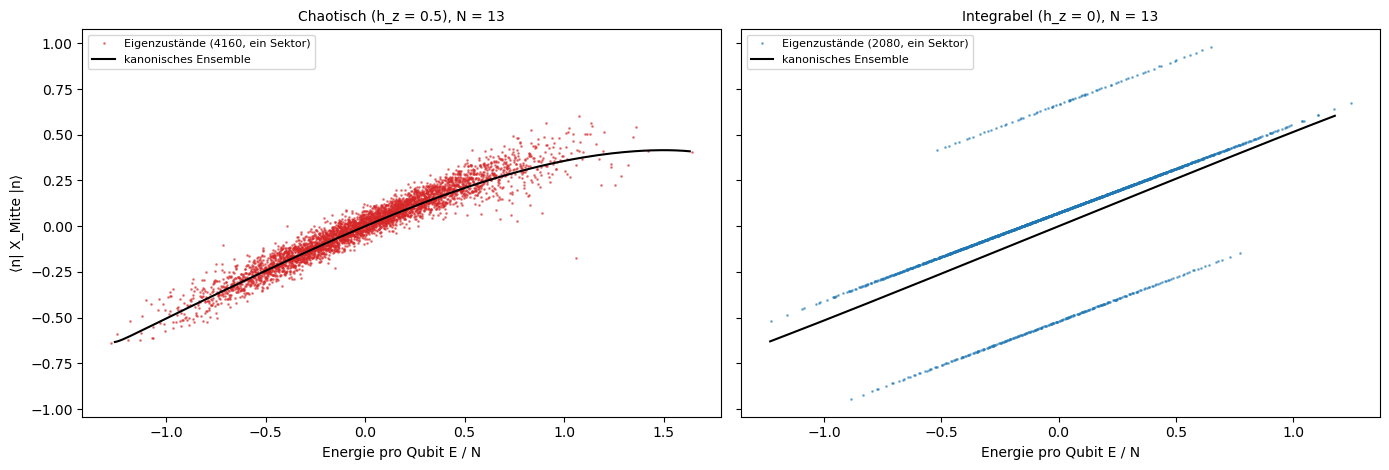

N = 13: Diagonalisierung aller Sektoren (15 s)


  chaotisch : Abweichung vom kanonischen Wert für |E/N| < 0.1 (787 Zustände): Mittel +0.011, Streuung 0.038, größte 0.131
  integrabel: Abweichung vom kanonischen Wert für |E/N| < 0.1 (412 Zustände): Mittel +0.017, Streuung 0.258, größte 0.670


In [2]:
N1 = 13
t0 = time.time()
data = {}
for label, hz in [("chaotisch", H_Z), ("integrabel", 0.0)]:
    H, A, secs = eigen_sectors(N1, hz)
    data[label] = dict(H=H, A=A, secs=secs, E=np.concatenate([s["E"] for s in secs]),
                       Ad=np.concatenate([np.diag(s["A"]) for s in secs]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
betas = np.linspace(-1.5, 3, 200)
for ax, label, c in [(axes[0], "chaotisch", "tab:red"), (axes[1], "integrabel", "tab:blue")]:
    d = data[label]
    main = d["secs"][0]
    th = np.array([thermal(d["E"], d["Ad"], b) for b in betas])
    ax.plot(main["E"] / N1, np.diag(main["A"]), ".", ms=2, alpha=0.5, c=c, label=f"Eigenzustände ({len(main['E'])}, ein Sektor)")
    ax.plot(th[:, 0] / N1, th[:, 1], "k-", lw=1.5, label="kanonisches Ensemble")
    ax.set_xlabel("Energie pro Qubit E / N")
    ax.set_title(f"{label.capitalize()} (h_z = {H_Z if label == 'chaotisch' else 0}), N = {N1}", fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("⟨n| X_Mitte |n⟩")
plt.tight_layout()
plt.show()

print(f"N = {N1}: Diagonalisierung aller Sektoren ({time.time() - t0:.0f} s)")
for label in data:
    d, main = data[label], data[label]["secs"][0]
    mid = np.abs(main["E"] / N1) < 0.1
    beta_mid = [beta_of_energy(d["E"], e) for e in main["E"][mid]]
    dev = np.diag(main["A"])[mid] - np.array([thermal(d["E"], d["Ad"], b)[1] for b in beta_mid])
    print(f"  {label:10s}: Abweichung vom kanonischen Wert für |E/N| < 0.1 ({mid.sum()} Zustände): "
          f"Mittel {dev.mean():+.3f}, Streuung {dev.std():.3f}, größte {np.abs(dev).max():.3f}")

* Das **linke Bild** zeigt die chaotische Kette: Die 4160 Punkte bilden ein schmales Band, das der kanonischen Kurve folgt; $A_{nn}$ ist also im Wesentlichen eine glatte Funktion der Energie, wie die ETH verlangt. An den Rändern des Spektrums, wo wenige Zustände liegen, ist das Band breiter.
* Das **rechte Bild** zeigt die integrable Kette: Die Punkte liegen auf drei scharfen Geraden statt in einem Band um die Kurve. Bei derselben Energie $E/N = 0$ gibt es Eigenzustände mit $A_{nn} \approx -0.5$, $0.1$ und $0.7$: Der Wert hängt außer von der Energie von den Besetzungen der Fermion-Moden ab (Theorie, Abschnitt 6). Dass es gerade Geraden sind, ist eine Besonderheit des kritischen Punkts $J = h_x$; mit einem anderen $h_x$ zerfallen sie in viele kürzere Äste (Variation 1). Die kanonische Kurve liegt knapp unter dem mittleren Ast und weit weg von den beiden anderen.
* Die **Ausgabe** vergleicht die Zustände nahe der Spektrumsmitte ($\vert E/N\vert < 0.1$) mit dem kanonischen Wert bei ihrer Energie: chaotisch im Mittel +0.011 mit einer Streuung von 0.038 (787 Zustände), integrabel +0.017 mit einer Streuung von 0.258 und Abweichungen bis 0.67 (412 Zustände).

##### *2. Wie schnell verschwinden die Schwankungen?*

Werden die Unterschiede zwischen benachbarten Eigenzuständen mit wachsender Kette kleiner, und wie schnell? Vorher vorhersagen: Um welchen Faktor sollte die Streuung nach der ETH schrumpfen, wenn die Kette zwei Qubits länger wird?

Für $N = 7, 9, 11, 13$ wird jeweils der Sektor diagonalisiert, der unter allen Symmetrien gerade ist. Gemessen wird die Streuung der Differenzen $A_{n+1,n+1} - A_{nn}$ benachbarter Eigenzustände in den mittleren 20 % des Spektrums, aufgetragen gegen die Sektordimension $D$ (Theorie, Abschnitt 4).

**Hintergrund & Fachbegriffe:**
- **Sektordimension $D$:** die Zahl der Zustände im Sektor; sie wächst wie $2^N$, also ist $D^{-1/2} \propto 2^{-N/2}$.
- **Entropie $S$:** der Logarithmus der Zahl der Zustände bei einer Energie; $e^{-S/2}$ und $D^{-1/2}$ fallen gleich schnell mit $N$.
- **Typizität:** Ein zufälliger Vektor in $D$ Dimensionen gibt für eine Observable fast immer denselben Wert, mit Schwankungen der Größe $D^{-1/2}$.

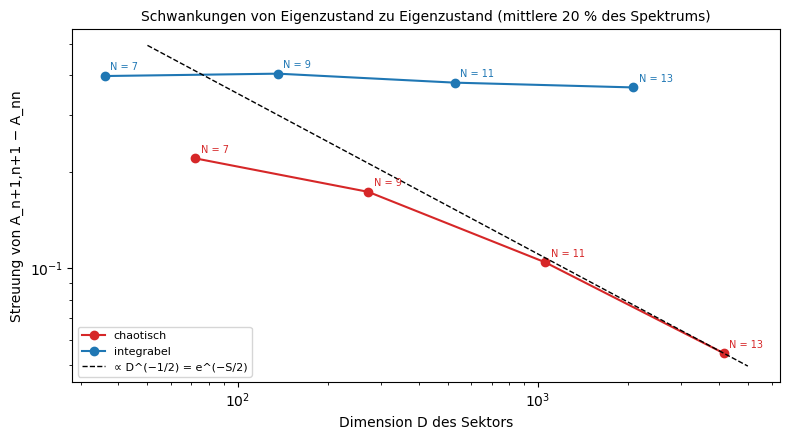

chaotisch : N = 7: D = 72, 0.221,  N = 9: D = 272, 0.173,  N = 11: D = 1056, 0.105,  N = 13: D = 4160, 0.054
integrabel: N = 7: D = 36, 0.398,  N = 9: D = 136, 0.405,  N = 11: D = 528, 0.380,  N = 13: D = 2080, 0.367
Steigung chaotisch zwischen N = 11 und 13: -0.48   (ETH: -0.5)


In [3]:
NS = [7, 9, 11, 13]
fluct = {"chaotisch": [], "integrabel": []}
dims = {"chaotisch": [], "integrabel": []}
for n in NS:
    for label, hz in [("chaotisch", H_Z), ("integrabel", 0.0)]:
        sec = data[label]["secs"][0] if n == N1 else eigen_sectors(n, hz, all_sectors=False)[2][0]
        fluct[label].append(neighbour_fluctuation(sec["E"], np.diag(sec["A"])))
        dims[label].append(len(sec["E"]))

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, c in [("chaotisch", "tab:red"), ("integrabel", "tab:blue")]:
    ax.loglog(dims[label], fluct[label], "o-", c=c, label=label)
    for n, D, f in zip(NS, dims[label], fluct[label]):
        ax.annotate(f"N = {n}", (D, f), textcoords="offset points", xytext=(4, 4), fontsize=7, color=c)
D_line = np.array([50, 5000])
ax.loglog(D_line, fluct["chaotisch"][-1] * np.sqrt(dims["chaotisch"][-1] / D_line), "k--", lw=1, label="∝ D^(−1/2) = e^(−S/2)")
ax.set_xlabel("Dimension D des Sektors")
ax.set_ylabel("Streuung von A_n+1,n+1 − A_nn")
ax.set_title("Schwankungen von Eigenzustand zu Eigenzustand (mittlere 20 % des Spektrums)", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for label in fluct:
    print(f"{label:10s}: " + ",  ".join(f"N = {n}: D = {D}, {f:.3f}" for n, D, f in zip(NS, dims[label], fluct[label])))
slope = np.polyfit(np.log(dims["chaotisch"][-2:]), np.log(fluct["chaotisch"][-2:]), 1)[0]
print(f"Steigung chaotisch zwischen N = 11 und 13: {slope:.2f}   (ETH: -0.5)")

* Das **Bild** zeigt die Streuung gegen $D$, doppelt logarithmisch. Die chaotische Kette (rot) fällt und nähert sich mit wachsendem $N$ der gestrichelten Geraden $\propto D^{-1/2}$; bei kleinen Ketten ist sie noch flacher, weil dort die Ränder des Spektrums und die geringe Zahl der Zustände eine Rolle spielen. Die integrable Kette (blau) bleibt fast waagrecht: Ihre Eigenzustände werden mit wachsender Kette nicht ähnlicher, weil die Sprünge zwischen den Ästen aus Experiment 1 bleiben.
* Die **Ausgabe** gibt chaotisch 0.221, 0.173, 0.105, 0.054 für $N = 7$ bis 13 und integrabel 0.398, 0.405, 0.380, 0.367. Zwischen $N = 11$ und 13 hat die chaotische Kurve die Steigung −0.48, nahe am ETH-Wert −0.5: Zwei Qubits mehr halbieren die Schwankung (Faktor $\sqrt4 = 2$, gemessen 1.9).

##### *3. Nichtdiagonalelemente: klein, glatt und gaußverteilt?*

Sind die Nichtdiagonalelemente klein, hängen sie glatt von der Frequenz ab, und sind sie gaußverteilt? Vorher vorhersagen: Was ergibt $D\cdot\langle\vert A_{mn}\vert^2\rangle$ für zwei verschiedene Kettenlängen, wenn die ETH gilt?

Gesammelt werden alle $A_{mn}$ mit $m \ne n$, deren mittlere Energie $(E_m + E_n)/2$ nahe der Spektrumsmitte liegt (Abstand höchstens 0.25), für $\omega = E_m - E_n$ bis 10. **Links:** der Mittelwert von $\vert A_{mn}\vert^2$ in Frequenzbins, multipliziert mit der Sektordimension $D$, für die chaotische Kette mit $N = 11$ und 13 und die integrable mit $N = 13$. **Rechts:** die Verteilung der Elemente im Fenster $1.0 < \omega < 1.2$, geteilt durch ihre Standardabweichung, mit einer Gauß-Kurve; dazu das Verhältnis $\Gamma$ (Theorie, Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **Frequenz $\omega$:** die Energiedifferenz zweier Eigenzustände; ein Element $A_{mn}$ trägt zur Dynamik mit $e^{i\omega t}$ bei.
- **$\vert f(\omega)\vert^2$:** die glatte Funktion der ETH; sie bestimmt, wie schnell $A$ nach einer Störung relaxiert.
- **$\Gamma = \langle A^2\rangle/\langle\vert A\vert\rangle^2$:** $\pi/2 \approx 1.57$ für eine Gauß-Verteilung, viel größer, wenn die meisten Elemente null und wenige groß sind.

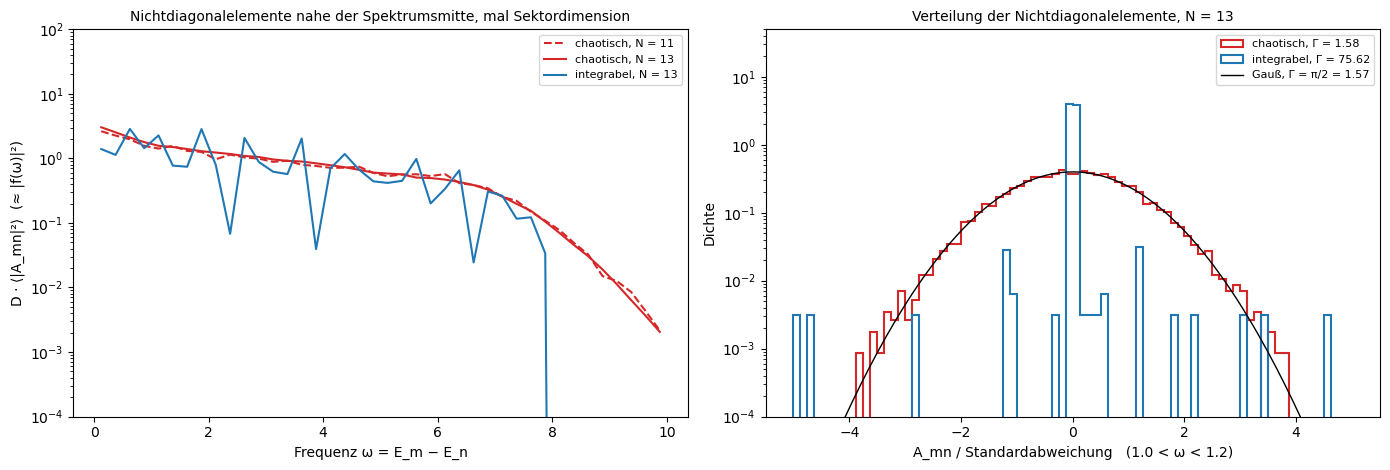

chaotisch : Γ = ⟨A²⟩/⟨|A|⟩² = 1.575 aus 9175 Elementen mit 1.0 < ω < 1.2, davon 9175 nicht null (|A| > 1e-10)
integrabel: Γ = ⟨A²⟩/⟨|A|⟩² = 75.621 aus 2573 Elementen mit 1.0 < ω < 1.2, davon 62 nicht null (|A| > 1e-10)
chaotisch, D·⟨|A_mn|²⟩ bei ω ≈ 0.1 / 2 / 6:  N = 11: 2.64 / 0.97 / 0.571,  N = 13: 3.04 / 1.23 / 0.470


In [4]:
off = {}
for label, hz in [("chaotisch", H_Z), ("integrabel", 0.0)]:
    for n in [11, 13]:
        sec = data[label]["secs"][0] if n == N1 else eigen_sectors(n, hz, all_sectors=False)[2][0]
        om, a = offdiagonal(sec)
        off[label, n] = dict(om=om, a=a, D=len(sec["E"]))
bins = np.linspace(0, 10, 41)
centres = 0.5 * (bins[1:] + bins[:-1])
def profile(om, a, D):
    """Mittelwert von D·|A_mn|² in Bins der Frequenz ω; ETH: D·|A_mn|² ≈ |f(ω)|², unabhängig von N."""
    k = np.digitize(om, bins)
    return np.array([D * np.mean(a[k == i] ** 2) if np.any(k == i) else np.nan for i in range(1, len(bins))])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for (label, n), ls in zip([("chaotisch", 11), ("chaotisch", 13), ("integrabel", 13)], ["--", "-", "-"]):
    o = off[label, n]
    axes[0].semilogy(centres, profile(o["om"], o["a"], o["D"]), ls, c="tab:red" if label == "chaotisch" else "tab:blue",
                     label=f"{label}, N = {n}")
axes[0].set_ylim(1e-4, 1e2)
axes[0].set_xlabel("Frequenz ω = E_m − E_n")
axes[0].set_ylabel("D · ⟨|A_mn|²⟩  (≈ |f(ω)|²)")
axes[0].set_title("Nichtdiagonalelemente nahe der Spektrumsmitte, mal Sektordimension", fontsize=10)
axes[0].legend(fontsize=8)
xx = np.linspace(-5, 5, 200)
gammas = {}
for label, c in [("chaotisch", "tab:red"), ("integrabel", "tab:blue")]:
    o = off[label, N1]
    a = o["a"][(o["om"] > 1.0) & (o["om"] < 1.2)]                      # schmales Frequenzfenster
    gammas[label] = (np.mean(a ** 2) / np.mean(np.abs(a)) ** 2, np.sum(np.abs(a) > 1e-10), len(a))
    axes[1].hist(a / a.std(), bins=np.linspace(-5, 5, 81), density=True, histtype="step", lw=1.5, color=c,
                 label=f"{label}, Γ = {gammas[label][0]:.2f}")
axes[1].plot(xx, np.exp(-xx ** 2 / 2) / np.sqrt(2 * np.pi), "k-", lw=1, label="Gauß, Γ = π/2 = 1.57")
axes[1].set_yscale("log")
axes[1].set_ylim(1e-4, 50)
axes[1].set_xlabel("A_mn / Standardabweichung   (1.0 < ω < 1.2)")
axes[1].set_ylabel("Dichte")
axes[1].set_title(f"Verteilung der Nichtdiagonalelemente, N = {N1}", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for label in gammas:
    G, nonzero, cnt = gammas[label]
    print(f"{label:10s}: Γ = ⟨A²⟩/⟨|A|⟩² = {G:.3f} aus {cnt} Elementen mit 1.0 < ω < 1.2, davon {nonzero} nicht null (|A| > 1e-10)")
pc11, pc13 = profile(off["chaotisch", 11]["om"], off["chaotisch", 11]["a"], off["chaotisch", 11]["D"]), profile(off["chaotisch", 13]["om"], off["chaotisch", 13]["a"], off["chaotisch", 13]["D"])
print(f"chaotisch, D·⟨|A_mn|²⟩ bei ω ≈ 0.1 / 2 / 6:  N = 11: {pc11[0]:.2f} / {pc11[8]:.2f} / {pc11[24]:.3f},  N = 13: {pc13[0]:.2f} / {pc13[8]:.2f} / {pc13[24]:.3f}")

* Das **linke Bild** zeigt $D\cdot\langle\vert A_{mn}\vert^2\rangle$ gegen $\omega$. Die beiden chaotischen Kurven (gestrichelt $N = 11$, durchgezogen $N = 13$) liegen fast aufeinander, obwohl sich $D$ um den Faktor 4 unterscheidet: Die Elemente selbst schrumpfen wie $D^{-1/2}$, und übrig bleibt eine glatte Funktion $\vert f(\omega)\vert^2$, die mit $\omega$ langsam und ab etwa 7 schneller abfällt. Die integrable Kurve zackt, weil nur wenige Übergänge beitragen, und bricht bei $\omega = 8$ ab: Größere Energien kann $X_c$ nicht übertragen, denn es erzeugt höchstens zwei Quasiteilchen mit je höchstens $2(J + h_x) = 4$ (Theorie, Abschnitt 6).
* Das **rechte Bild** zeigt die Verteilung im Fenster $1.0 < \omega < 1.2$. Die chaotischen Elemente (rot) folgen der Gauß-Kurve über fast drei Größenordnungen der Dichte. Die integrablen (blau) haben eine hohe Spitze bei 0, das sind die exakt verschwindenden Elemente, und einige vereinzelte große Werte.
* Die **Ausgabe** gibt $\Gamma = 1.575$ für die chaotische Kette (9175 Elemente, Gauß: 1.571) und $\Gamma = 75.6$ für die integrable: Von ihren 2573 Elementen im Fenster sind nur 62 nicht null. $D\cdot\langle\vert A_{mn}\vert^2\rangle$ ist bei $\omega \approx 0.1$, 2 und 6 für $N = 11$ und 13: 2.64 und 3.04, 0.97 und 1.23, 0.57 und 0.47; die Abweichungen von etwa 20 % zeigen, dass $D$ nur ungefähr proportional zu $e^{S}$ in der Spektrumsmitte ist.

##### *4. Vergisst die Kette ihren Anfangszustand?*

Erreicht die Kette nach einem Quench den thermischen Wert, unabhängig davon, wie der Anfangszustand im Einzelnen aussah? Vorher vorhersagen: Wie weit streuen die Langzeitwerte vieler verschiedener Anfangszustände um den thermischen Wert, chaotisch und integrabel?

60 zufällige Produktzustände (jedes Qubit zeigt in eine zufällige Richtung auf der Bloch-Kugel) sind die Anfangszustände; ihre Energien liegen nahe der Spektrumsmitte. Für jeden wird der Langzeitwert aus dem diagonalen Ensemble berechnet (Theorie, Abschnitt 1) und mit dem kanonischen Wert bei derselben Energie verglichen. **Links:** die Zeitentwicklung $\langle X_c(t)\rangle$ für den Zustand, bei dem die integrable Kette am weitesten vom thermischen Wert abweicht, mit beiden Vorhersagen. **Rechts:** Langzeitwert gegen thermischen Wert für alle 60 Zustände.

**Hintergrund & Fachbegriffe:**
- **Quench:** Das System wird in einem einfachen Zustand präpariert, der kein Eigenzustand ist, und dann unter $H$ sich selbst überlassen.
- **Produktzustand:** ein Zustand ohne Verschränkung, jedes Qubit für sich; seine Energie ist leicht auszurechnen.
- **Diagonales Ensemble:** $\sum_n\vert c_n\vert^2A_{nn}$, das Zeitmittel für unendlich lange Zeiten.
- **Verallgemeinertes Gibbs-Ensemble:** der Gleichgewichtszustand eines integrablen Systems, der alle Erhaltungsgrößen festhält.

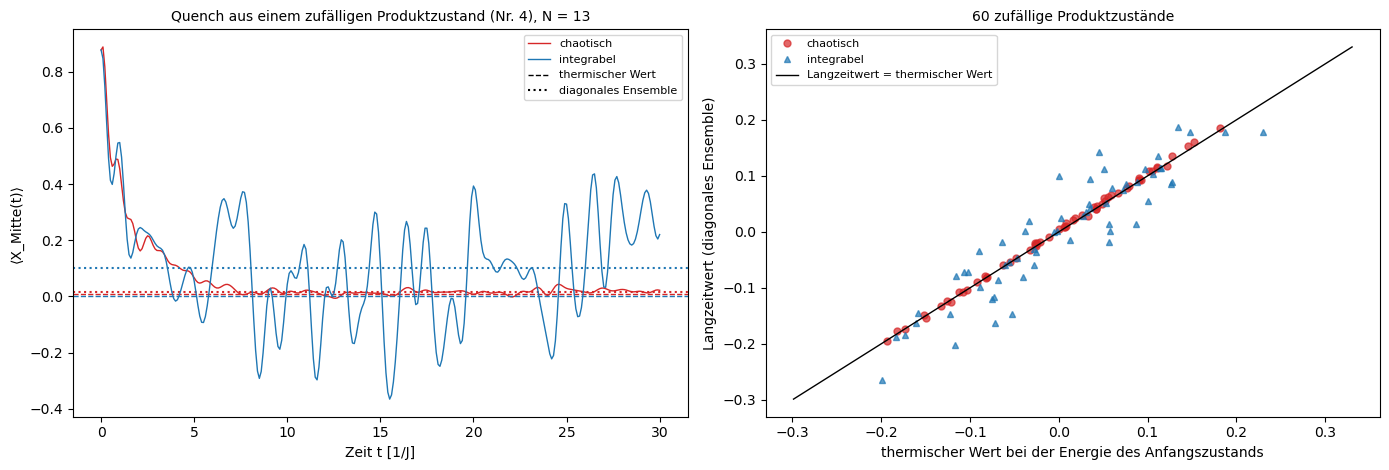

Energien der 60 Zustände: E/N von -0.40 bis 0.43 (chaotische Kette)
chaotisch : Langzeitwert − thermischer Wert: Mittel +0.003, Streuung 0.003, größte 0.009
integrabel: Langzeitwert − thermischer Wert: Mittel -0.003, Streuung 0.042, größte 0.100
Zustand Nr. 4, chaotisch : thermisch +0.008, diagonales Ensemble +0.015, Zeitmittel t > 10: +0.016
Zustand Nr. 4, integrabel: thermisch +0.000, diagonales Ensemble +0.100, Zeitmittel t > 10: +0.079


In [5]:
rng = np.random.default_rng(3)
def random_product_state(n):
    """Jedes Qubit zeigt in eine zufällige Richtung auf der Bloch-Kugel (gleichverteilt)."""
    psi = np.array([1.0 + 0j])
    for _ in range(n):
        th, ph = np.arccos(rng.uniform(-1, 1)), rng.uniform(0, 2 * np.pi)
        psi = np.kron(psi, [np.cos(th / 2), np.exp(1j * ph) * np.sin(th / 2)])
    return psi

def diagonal_ensemble(d, psi):
    """Langzeitmittel Σ_n |c_n|² A_nn über alle Sektoren (Theorie, Abschnitt 1)."""
    return sum((np.abs(s["U"].T @ (s["V"].T @ psi)) ** 2 * np.diag(s["A"])).sum() for s in d["secs"])

states = [random_product_state(N1) for _ in range(60)]
quench = {}
for label in data:
    d = data[label]
    rows = []
    for psi in states:
        energy = np.vdot(psi, d["H"] @ psi).real
        rows.append((energy / N1, thermal(d["E"], d["Ad"], beta_of_energy(d["E"], energy))[1], diagonal_ensemble(d, psi)))
    quench[label] = np.array(rows)
k_show = np.argmax(np.abs(quench["integrabel"][:, 2] - quench["integrabel"][:, 1]))
ts = np.linspace(0, 30, 301)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for label, c in [("chaotisch", "tab:red"), ("integrabel", "tab:blue")]:
    d = data[label]
    traj = expm_multiply(-1j * d["H"], states[k_show], start=0, stop=ts[-1], num=len(ts), endpoint=True)
    At = np.array([np.vdot(v, d["A"] @ v).real for v in traj])
    axes[0].plot(ts, At, c=c, lw=1, label=f"{label}")
    axes[0].axhline(quench[label][k_show, 1], color=c, ls="--", lw=1)
    axes[0].axhline(quench[label][k_show, 2], color=c, ls=":", lw=1.5)
    quench[label + "_late"] = At[ts > 10].mean()
axes[0].plot([], [], "k--", lw=1, label="thermischer Wert")
axes[0].plot([], [], "k:", lw=1.5, label="diagonales Ensemble")
axes[0].set_xlabel("Zeit t [1/J]")
axes[0].set_ylabel("⟨X_Mitte(t)⟩")
axes[0].set_title(f"Quench aus einem zufälligen Produktzustand (Nr. {k_show}), N = {N1}", fontsize=10)
axes[0].legend(fontsize=8)
for label, c, m in [("chaotisch", "tab:red", "o"), ("integrabel", "tab:blue", "^")]:
    q = quench[label]
    axes[1].plot(q[:, 1], q[:, 2], m, c=c, ms=5, alpha=0.7, label=label)
lim = [min(quench["chaotisch"][:, 1].min(), quench["integrabel"][:, 1].min()) - 0.1, max(quench["chaotisch"][:, 1].max(), quench["integrabel"][:, 1].max()) + 0.1]
axes[1].plot(lim, lim, "k-", lw=1, label="Langzeitwert = thermischer Wert")
axes[1].set_xlabel("thermischer Wert bei der Energie des Anfangszustands")
axes[1].set_ylabel("Langzeitwert (diagonales Ensemble)")
axes[1].set_title("60 zufällige Produktzustände", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Energien der 60 Zustände: E/N von {quench['chaotisch'][:, 0].min():.2f} bis {quench['chaotisch'][:, 0].max():.2f} (chaotische Kette)")
for label in ["chaotisch", "integrabel"]:
    diff = quench[label][:, 2] - quench[label][:, 1]
    print(f"{label:10s}: Langzeitwert − thermischer Wert: Mittel {diff.mean():+.3f}, Streuung {diff.std():.3f}, größte {np.abs(diff).max():.3f}")
for label in ["chaotisch", "integrabel"]:
    print(f"Zustand Nr. {k_show}, {label:10s}: thermisch {quench[label][k_show, 1]:+.3f}, diagonales Ensemble {quench[label][k_show, 2]:+.3f}, "
          f"Zeitmittel t > 10: {quench[label + '_late']:+.3f}")

* Das **linke Bild** zeigt einen Quench. Beide Ketten starten bei $\langle X_c\rangle = 0.88$ und fallen in wenigen Zeiteinheiten ab. Die chaotische Kette (rot) kommt nach $t \approx 6$ zur Ruhe, mit kleinen Schwankungen um ihren Langzeitwert 0.015, nahe am thermischen Wert 0.008. Die integrable Kette (blau) schwankt dauerhaft stark, zwischen etwa −0.35 und 0.45, um ihren Langzeitwert 0.100, der deutlich über dem thermischen Wert 0.000 liegt; ihr Zeitmittel ab $t = 10$ ist 0.079, wegen der großen Schwankungen noch nicht ganz am Langzeitwert.
* Das **rechte Bild** zeigt alle 60 Zustände. Die chaotischen Punkte (rot) liegen auf der Diagonalen: Der Langzeitwert ist durch die Energie festgelegt. Die integrablen Punkte (blau) streuen weit um die Diagonale: Zwei Anfangszustände mit derselben Energie enden bei verschiedenen Werten, weil die Kette sich an die Besetzungen ihrer Fermion-Moden erinnert.
* Die **Ausgabe** gibt die Abweichung des Langzeitwerts vom thermischen Wert: chaotisch im Mittel +0.003 mit Streuung 0.003 und höchstens 0.009, integrabel im Mittel −0.003, aber mit Streuung 0.042 und bis zu 0.100. Die Energien der Zustände liegen bei $E/N$ zwischen −0.40 und 0.43, also bei hohen Temperaturen.

#### **Ergebnis**

Beim Lauf vom 2026-10-24 (Observable $X$ auf dem mittleren Qubit):

- **Diagonalelemente (Experiment 1):** In der chaotischen Kette ($N = 13$, $h_z = 0.5$) liegen die $A_{nn}$ in einem schmalen Band um die kanonische Kurve; nahe der Spektrumsmitte weichen sie im Mittel um +0.011 vom kanonischen Wert ab, mit einer Streuung von 0.038. In der integrablen Kette liegen sie auf drei getrennten Geraden; Streuung um den kanonischen Wert 0.258, Abweichungen bis 0.67.
- **Schwankungen (Experiment 2):** chaotisch 0.221, 0.173, 0.105, 0.054 für $N = 7$ bis 13, zwischen $N = 11$ und 13 mit der Steigung −0.48 gegen $D$ (ETH: −0.5); integrabel 0.398 bis 0.367, fast ohne Abnahme.
- **Nichtdiagonalelemente (Experiment 3):** chaotisch fällt $D\cdot\langle\vert A_{mn}\vert^2\rangle$ für $N = 11$ und 13 ungefähr auf dieselbe glatte Kurve $\vert f(\omega)\vert^2$, und die Elemente sind gaußverteilt, $\Gamma = 1.575$ (Gauß: 1.571). Integrabel sind von 2573 Elementen im Fenster $1.0 < \omega < 1.2$ nur 62 nicht null, $\Gamma = 75.6$, und oberhalb von $\omega = 8$ gibt es keine Übergänge.
- **Quench (Experiment 4):** Für 60 zufällige Produktzustände weicht der Langzeitwert der chaotischen Kette höchstens um 0.009 vom thermischen Wert ab (Streuung 0.003), der der integrablen bis zu 0.100 (Streuung 0.042). Die chaotische Kette vergisst ihren Anfangszustand bis auf seine Energie, die integrable nicht.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Abseits des kritischen Punkts:** In Experiment 1 für die integrable Kette `H_X = 0.7` setzen (oder `1.3`). *(Vorhersage: Die drei Geraden zerfallen in viele kürzere, schräge Äste; eine einzige glatte Kurve ergibt sich weiterhin nicht.)*
2. **Eine andere Observable:** In `eigen_sectors` statt `site_x` die Observable $Z$ auf dem mittleren Qubit nehmen (eine Diagonalmatrix mit den Einträgen $\pm1$). *(Vorhersage: Für die chaotische Kette gilt die ETH ebenso; die Schwankungen sind 0.107 bei $N = 11$ und 0.055 bei $N = 13$, fast dieselben wie für $X$. Für die integrable Kette ist $Z_c$ keine lokale Größe der Fermionen und vertauscht nicht mit dem Spin-Flip; die Diagonalelemente in einem Flip-Sektor sind null.)*
3. **Schwache Integrabilitätsbrechung:** `H_Z = 0.05` in den Experimenten 2 und 3. *(Vorhersage: Die Schwankungen sind größer als bei $h_z = 0.5$, 0.34, 0.20, 0.10 für $N = 9, 11, 13$, schrumpfen aber schneller als $D^{-1/2}$, und $\Gamma$ liegt bei 1.9 bis 2.6 zwischen Gauß und integrabel: Die Kette ist auf dem Weg zur ETH, wie in [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb), Experiment 3.)*
4. **Ein geordneter Anfangszustand:** In Experiment 4 den Néel-Zustand $\vert0101\dots0\rangle$ statt der zufälligen Zustände. *(Vorhersage: Seine Energie ist niedrig, $E/N \approx -0.9$, also eine tiefe Temperatur; dort ist die ETH bei 13 Qubits schlechter erfüllt, und auch die chaotische Kette weicht um etwa 0.02 vom thermischen Wert ab.)*
5. **Mikrokanonisch statt kanonisch:** In Experiment 1 zusätzlich das gleitende Mittel der $A_{nn}$ über je 100 benachbarte Eigenzustände zeichnen (das mikrokanonische Ensemble). *(Vorhersage: Es liegt mitten im roten Band und nahe der Spektrumsmitte etwa 0.01 über der kanonischen Kurve; das ist der Unterschied der beiden Ensembles bei 13 Qubits, der für große Systeme verschwindet.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum ist Thermalisierung in einem abgeschlossenen Quantensystem überhaupt ein Rätsel?</summary>

Die Zeitentwicklung ist unitär: Ein reiner Zustand bleibt rein, und keine Information über den Anfangszustand geht verloren. Trotzdem relaxieren lokale Größen auf thermische Werte, die nur von der Energie abhängen. Thermalisierung kann also nur für lokale Observablen gelten, nicht für den globalen Zustand.
</details>

<details><summary>2. Was ist das diagonale Ensemble, und wann ist es das Langzeitmittel?</summary>

$\sum_n\vert c_n\vert^2A_{nn}$ mit den Gewichten des Anfangszustands in der Eigenbasis. Es ist das Zeitmittel, wenn alle Energiedifferenzen verschieden sind, sodass sich die Phasen $e^{i(E_m - E_n)t}$ der Nichtdiagonalterme herausmitteln.
</details>

<details><summary>3. Was sagt die ETH über die Matrixelemente einer lokalen Observablen?</summary>

$A_{mn} = \mathcal A(\bar E)\delta_{mn} + e^{-S/2}f(\bar E, \omega)R_{mn}$: Die Diagonalelemente sind eine glatte Funktion der Energie, die Nichtdiagonalelemente exponentiell klein, mit einer glatten Funktion $f$ der Frequenz und zufälligen, gaußverteilten Vorzeichen und Beträgen $R_{mn}$.
</details>

<details><summary>4. Warum folgt aus der ETH, dass der Anfangszustand vergessen wird?</summary>

Liegen die Gewichte $\vert c_n\vert^2$ in einem schmalen Energiefenster, ist $\sum\vert c_n\vert^2A_{nn} \approx \mathcal A(E)$, egal wie die Gewichte im Fenster verteilt sind. Nur die Energie zählt; in Experiment 4 weichen 60 verschiedene Anfangszustände höchstens um 0.009 vom thermischen Wert ab.
</details>

<details><summary>5. Wie schnell schrumpfen die Schwankungen zwischen benachbarten Eigenzuständen, und warum?</summary>

Wie $e^{-S/2} \propto D^{-1/2}$, also um den Faktor $\sqrt2$ pro zusätzlichem Qubit. Chaotische Eigenzustände verhalten sich für lokale Observablen wie Zufallsvektoren, deren Erwartungswerte in $D$ Dimensionen um $D^{-1/2}$ schwanken (Typizität). Gemessen: Steigung −0.48.
</details>

<details><summary>6. Warum gilt die ETH in der integrablen Ising-Kette nicht?</summary>

Sie hat $N$ Erhaltungsgrößen, die Besetzungen der Fermion-Moden. Eigenzustände gleicher Energie können verschiedene Besetzungen haben, und $A_{nn}$ hängt von ihnen ab: Die Werte liegen auf getrennten Ästen statt auf einer Kurve, und ihre Schwankungen schrumpfen nicht.
</details>

<details><summary>7. Was beschreibt das verallgemeinerte Gibbs-Ensemble?</summary>

Den Gleichgewichtszustand eines integrablen Systems: $e^{-\sum_k\lambda_kI_k}/Z$ mit einem Parameter pro Erhaltungsgröße, festgelegt durch die Werte des Anfangszustands. Es erklärt, warum zwei Anfangszustände mit derselben Energie in der integrablen Kette bei verschiedenen Langzeitwerten enden.
</details>

<details><summary>8. Was misst die Funktion f(ω), und warum fallen die Kurven für N = 11 und 13 aufeinander?</summary>

$\vert f(\omega)\vert^2$ ist das Spektrum der Fluktuationen von $A$, die Fourier-Transformierte seiner Autokorrelation. Die Elemente selbst schrumpfen wie $D^{-1/2}$; multipliziert mit $D$ bleibt die von $N$ unabhängige Funktion $\vert f\vert^2$.
</details>

<details><summary>9. Wozu dient das Verhältnis Γ, und welche Werte ergeben sich?</summary>

Es prüft die Gauß-Verteilung ohne Histogramm: $\Gamma = \langle A^2\rangle/\langle\vert A\vert\rangle^2 = \pi/2 \approx 1.57$ für eine reelle Gauß-Verteilung. Chaotisch 1.575, integrabel 75.6, weil fast alle Elemente null und wenige groß sind.
</details>

<details><summary>10. Warum sind in der integrablen Kette fast alle Nichtdiagonalelemente von X in der Mitte null, und warum gibt es keine Übergänge über ω = 8?</summary>

$X_c$ ist in den Fermionen quadratisch und ändert höchstens zwei Mode-Besetzungen. Die meisten Paare von Eigenzuständen unterscheiden sich in mehr Moden, und zwei Quasiteilchen tragen höchstens $2\cdot2(J + h_x) = 8$ Energie.
</details>

<details><summary>11. Was bedeutet eine negative Temperatur?</summary>

Das Spektrum einer Spinkette ist nach oben beschränkt. Zu Energien oberhalb der Spektrumsmitte gehört ein kanonisches Ensemble mit $\beta < 0$, das hohe Energien stärker gewichtet als niedrige.
</details>

<details><summary>12. Wo stößt die ETH an Grenzen?</summary>

Bei nichtlokalen Observablen, an den Rändern des Spektrums, in integrablen und vielteilchenlokalisierten Systemen und bei Quanten-Narben, einzelnen nicht thermischen Eigenzuständen. In endlichen Systemen gilt sie nur bis auf Korrekturen, bei 13 Qubits einige Prozent.
</details>

<details><summary>13. Wie hängt die ETH mit Niveauabstoßung und Page-Kurve zusammen?</summary>

Alle drei kommen daher, dass chaotische Eigenzustände sich wie Zufallsvektoren mit fester Energie verhalten: Ihre Energien sind korreliert wie die Eigenwerte von Zufallsmatrizen, ihre Erwartungswerte sind thermisch, und ihre Verschränkung ist fast maximal, wie bei Page.
</details>

#### **Nächste Schritte**

- **Krylov-Komplexität:** wie schnell $X_c$ unter der Zeitentwicklung in immer komplexere Operatoren wächst, gemessen mit den Lanczos-Koeffizienten; das nächste Notebook der Serie, `chaos_krylov`.
- **Vielteilchenlokalisierung:** Mit starker Unordnung verletzt auch eine wechselwirkende Kette die ETH; das letzte geplante Notebook, `chaos_mbl`.
- **Detailliertes Gleichgewicht:** Außerhalb der Spektrumsmitte unterscheiden sich Übergänge zu höheren und zu niedrigeren Energien um den Faktor $e^{\beta\omega}$, weil die Zustandsdichte mit der Energie wächst; daraus folgt die Fluktuations-Dissipations-Beziehung, die sich mit denselben Daten prüfen lässt.
- **Verschränkung der Eigenzustände:** die Verschränkungsentropie jedes Eigenzustands gegen seine Energie, verglichen mit der thermischen Entropie; chaotische Zustände folgen einem Volumengesetz.
- **GGE ausrechnen:** Für die freien Fermionen lässt sich das verallgemeinerte Gibbs-Ensemble aus den Besetzungen $\langle n_k\rangle$ des Anfangszustands direkt berechnen und mit dem diagonalen Ensemble aus Experiment 4 vergleichen.
- **Experimente:** Thermalisierung einzelner Eigenzustände wurde mit ultrakalten Atomen in optischen Gittern gemessen (Kaufman et al. 2016).

#### **Referenzen**

- Deutsch, J. M. (1991): *Quantum statistical mechanics in a closed system*, Phys. Rev. A 43, 2046.
- Srednicki, M. (1994): *Chaos and quantum thermalization*, Phys. Rev. E 50, 888.
- Srednicki, M. (1999): *The approach to thermal equilibrium in quantized chaotic systems*, J. Phys. A 32, 1163 (die Form mit $f(\bar E, \omega)$).
- Kinoshita, T., Wenger, T. & Weiss, D. S. (2006): *A quantum Newton's cradle*, Nature 440, 900.
- Rigol, M., Dunjko, V., Yurovsky, V. & Olshanii, M. (2007): *Relaxation in a completely integrable many-body quantum system*, Phys. Rev. Lett. 98, 050405 (verallgemeinertes Gibbs-Ensemble).
- Rigol, M., Dunjko, V. & Olshanii, M. (2008): *Thermalization and its mechanism for generic isolated quantum systems*, Nature 452, 854.
- Kim, H., Ikeda, T. N. & Huse, D. A. (2014): *Testing whether all eigenstates obey the eigenstate thermalization hypothesis*, Phys. Rev. E 90, 052105.
- Beugeling, W., Moessner, R. & Haque, M. (2014): *Finite-size scaling of eigenstate thermalization*, Phys. Rev. E 89, 042112.
- D'Alessio, L., Kafri, Y., Polkovnikov, A. & Rigol, M. (2016): *From quantum chaos and eigenstate thermalization to statistical mechanics and thermodynamics*, Adv. Phys. 65, 239 (Abschnitt 4 und 6).
- Kaufman, A. M. et al. (2016): *Quantum thermalization through entanglement in an isolated many-body system*, Science 353, 794.
- LeBlond, T., Mallayya, K., Vidmar, L. & Rigol, M. (2019): *Entanglement and matrix elements of observables in interacting integrable systems*, Phys. Rev. E 100, 062134 (das Verhältnis $\Gamma$).